# Retinal OCT Denoising — Non-Local Means with a Fractional Compact Finite Difference Kernel

Implementation of **Chen & Gao (2022)**, *"Non-Local Mean Denoising Algorithm Based on Fractional Compact Finite
Difference Scheme Effectively Reduces Speckle Noise in Optical Coherence Tomography Images"*, Micromachines 13, 2039.

**Dataset** — Duke SD-OCT 2012 (`Sparsity_SDOCT_DATASET_2012`, Fang et al. [15] of the paper).
This is the "DUKE" set of the paper's Tables 3–4: every case has a noisy **raw** B-scan, a registered frame-**averaged**
image used as the clean label, and the **MSBTD** result of Fang et al.

**Pipeline (Algorithm 1 of the paper)**

```
noisy v ──► replicate borders ──► FCFDS masks (Tables 1–2) ──► Δx^α, Δy^α ──► φy = 1 / (1 + (Δx^α + Δy^α)/η)   (Eq. 12)
                                                                                   │
        patch kernel R(Δ,x) = exp(-(σx²/2φx + σy²/2φy))  (Eq. 11) ◄────────────────┘
        weights  ω(x,t) = exp(-Σ_Δ R(Δ,x)(v(x+Δ)-v(t+Δ))² / h²)  (Eq. 10)
        output   v̂(x) = Σ_t ω v(t) / Σ_t ω  over the search window  (Eq. 13)
```

Compared methods: NLM with the traditional **uniform** patch kernel (the paper's ablation, Figs. 4–5), NLM with an
isotropic **Gaussian** kernel (the "traditional isotropic Gaussian similarity weighting" of the conclusions), the
proposed **FCFDS** kernel, and **MSBTD** from the dataset. NCDF, PNLM, WGLRR and PBFD from the paper's tables have no public implementation here and are not rerun;
their numbers are quoted from the paper at the end. Metrics: PSNR and SSIM against the averaged image (Tables 3–4) and
Canny edge maps (Fig. 6).

In [1]:
import os
import time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import pywt
import scipy.io as sio
import matplotlib.pyplot as plt
from PIL import Image
from skimage.feature import canny
from skimage.metrics import structural_similarity
from tqdm.auto import tqdm

## 1. Configuration

The paper does not report its parameter values (search window `l`, patch size `k`, α, N, φx, η, h), so the defaults
below are common NLM choices plus a fractional order in the middle of (0, 1). The filtering strength is given as a
**normalised** factor: $h = h_f\,\hat\sigma\,\sqrt{\bar m_R}$, where $\hat\sigma$ is the MAD noise estimate of the
B-scan and $\bar m_R = \text{mean}_x \sum_\Delta R(\Delta,x)$ is the average mass of the patch kernel. This makes
$h_f$ comparable between kernels of different size; $h_f$ is then tuned per kernel on one image (Section 5).

In [2]:
DUKE_DIR = Path(os.environ.get("OCT_DUKE_DIR", "Sparsity_SDOCT_DATASET_2012"))
TUNE_IMAGE = "Image 1"                              # parameters are tuned on this case only
DEMO_IMAGES = ["Image 5", "Image 9"]                # walk-through figures (cf. Figs. 2 and 3)

# NLM windows
SEARCH = 21           # search window l x l  (F(x) in Eq. 13)
PATCH = 7             # similarity window k x k  (σx, σy ∈ [-3, 3])

# FCFDS operator
ALPHA = 0.5           # fractional order α ∈ (0, 1)
N_TAPS = 4            # mask length N (even, Eq. 9)
PHI_X = 4.0           # constant horizontal variance φx of the kernel (Eq. 11)
ETA = None            # damping coefficient η of Eq. 12; None -> mean of |Δx^α| + |Δy^α| over the image

# Isotropic Gaussian baseline kernel variance
PHI_GAUSS = 4.0

# Normalised filtering strengths tried during tuning
H_GRID = [1.0, 1.4, 2.0, 2.8, 3.6, 4.6]
ALPHA_GRID = [0.3, 0.5, 0.8]

MAX_VAL = 255.0
N_WORKERS = min(8, os.cpu_count() or 1)    # numpy releases the GIL in the NLM loop, so threads run in parallel
OUT_DIR = Path("outputs") / "duke_nlm"
SAVE_DENOISED = True
OUT_DIR.mkdir(parents=True, exist_ok=True)

## 2. Load the dataset

Only the registered raw / averaged pair in each numbered case folder is used (the `Distant/` and `Unregistered/`
sub-folders of cases 1 and 2 are other acquisitions that are not aligned with the raw scan).

In [3]:
def list_duke(root=DUKE_DIR):
    rows = []
    for case in sorted((d for d in root.iterdir() if d.is_dir() and d.name.isdigit()), key=lambda d: int(d.name)):
        rows.append({
            "image": f"Image {case.name}",
            "raw": next(case.glob("*Raw Image.tif")),
            "ref": next(case.glob("*Averaged Image.tif")),
            "msbtd": next(case.glob("*MSBTD*.mat"), None),   # "*_MSBTD result.mat" or "*_MSBTD result_result.mat"
        })
    return pd.DataFrame(rows)


def load_gray(path):
    return np.asarray(Image.open(path).convert("L"), dtype=np.float64)


def load_msbtd(path):
    mat = sio.loadmat(path)
    return next(v for k, v in mat.items() if not k.startswith("__")).astype(np.float64)


def optional(row, col, loader):
    return loader(row[col]) if isinstance(row[col], Path) else None


images = list_duke()
print(f"Duke SD-OCT 2012: {len(images)} cases from {DUKE_DIR.resolve()}")
images.assign(**{c: images[c].map(lambda p: getattr(p, "name", None)) for c in ["raw", "ref", "msbtd"]})

Duke SD-OCT 2012: 17 cases from C:\Users\sidhe\OneDrive\Desktop\Acads\Semester-5\Digital_Signal_Processing\Mini_Project\Wavelet_Transform\Sparsity_SDOCT_DATASET_2012


,image,raw,ref,msbtd
0,Image 1,1_Raw Image.tif,1_Averaged Image.tif,1_MSBTD result.mat
1,Image 2,2_R_Raw Image.tif,2_R_Averaged Image.tif,R_2_MSBTD result.mat
2,Image 3,3_Raw Image.tif,3_Averaged Image.tif,R_3_MSBTD result.mat
3,Image 4,4_Raw Image.tif,4_Averaged Image.tif,4_MSBTD result.mat
4,Image 5,5_Raw Image.tif,5_Averaged Image.tif,5_MSBTD result.mat
5,Image 6,6_Raw Image.tif,6_Averaged Image.tif,6_MSBTD result_result.mat
6,Image 7,7_Raw Image.tif,7_Averaged Image.tif,7_MSBTD result_result.mat
7,Image 8,8_Raw Image.tif,8_Averaged Image.tif,8_MSBTD result_result.mat
8,Image 9,9_Raw Image.tif,9_Averaged Image.tif,R_9_MSBTD result_result.mat
9,Image 10,10_Raw Image.tif,10_Averaged Image.tif,R_10_MSBTD result_result.mat


## 3. The FCFDS operator (Lemmas 1–2, Eqs. 5–9)

The shifted Grünwald operator uses the weights $g_k^{(\alpha)} = (-1)^k\binom{\alpha}{k}$, computed with the recursion
$g_0 = 1,\; g_k = g_{k-1}\,(k-1-\alpha)/k$. The compact scheme combines three shifted Grünwald sums (shifts 0, −1, −2,
Eq. 6) with weights $\rho_1, \rho_2, \rho_3$, so with $\beta = 1$ pixel the coefficient of $f(x-j)$ is (Eq. 7)

$$c_{j+1} = \rho_1 g_j + \rho_2 g_{j-1} + \rho_3 g_{j-2}, \qquad g_{<0} = 0,\quad j = 0,\dots,N-1,$$

i.e. $c_1 = \rho_1$, $c_2 = -\alpha\rho_1 + \rho_2$, … as in Eq. 9 (Eq. 9's general term writes $g_k$ where Eq. 7 has
$g_{k-1}$; Eq. 7 is used).

**Correction to Eq. 5.** For the scheme to be consistent, the weights must satisfy $\sum\rho_i = 1$,
$\sum\rho_i(s_i-\alpha/2) = 0$ and $\sum\rho_i\big(s_i^2/2-\alpha s_i/2+\alpha^2/8+\alpha/24\big) = 0$ for the shifts
$s = (0,-1,-2)$ (expanding the symbol of $S^{(\alpha)}_{\beta,s}$). Solving gives
$$\rho_1 = \frac{24+17\alpha+3\alpha^2}{24},\quad \rho_2 = -\frac{11\alpha+3\alpha^2}{12},\quad \rho_3 = \frac{5\alpha+3\alpha^2}{24},$$
which matches the paper's $\rho_1$ and $\rho_3$, while the printed $\rho_2$ has denominator 24 (then $\sum\rho_i \neq 1$
and a constant image would not have a near-zero derivative). The corrected $\rho_2$ is used; the check is printed below.

**Masks (Tables 1–2).** Each derivative is an $N$-tap causal 1-D mask — $\Delta^\alpha_x$ runs along the horizontal axis
(image columns) and $\Delta^\alpha_y$ along the vertical axis (image rows), each over the current pixel and the $N-1$
pixels before it. Borders are replicated (Algorithm 1, step 3).

In [4]:
def fcfds_rho(alpha):
    return ((24 + 17 * alpha + 3 * alpha ** 2) / 24,
            -(11 * alpha + 3 * alpha ** 2) / 12,
            (5 * alpha + 3 * alpha ** 2) / 24)


def fcfds_coeffs(alpha=ALPHA, n_taps=N_TAPS):
    g = np.ones(n_taps)
    for j in range(1, n_taps):
        g[j] = g[j - 1] * (j - 1 - alpha) / j
    rho1, rho2, rho3 = fcfds_rho(alpha)
    c = rho1 * g
    c[1:] += rho2 * g[:-1]
    c[2:] += rho3 * g[:-2]
    return c


def frac_diff(f, c, axis):
    # D[i] = sum_j c[j] * f[i - j] along `axis`, with replicated borders
    n = len(c)
    pad = [(0, 0), (0, 0)]
    pad[axis] = (n - 1, 0)
    fp = np.pad(f, pad, mode="edge")
    L = f.shape[axis]
    return sum(c[j] * np.take(fp, np.arange(n - 1 - j, n - 1 - j + L), axis=axis) for j in range(n))


def fcfds_gradients(img, alpha=ALPHA, n_taps=N_TAPS):
    c = fcfds_coeffs(alpha, n_taps)
    return frac_diff(img, c, axis=1), frac_diff(img, c, axis=0)    # (Δx^α, Δy^α)


for a in [0.3, ALPHA, 0.8]:
    print(f"α={a}: ρ={np.round(fcfds_rho(a), 4)}  Σρ={sum(fcfds_rho(a)):.6f}  "
          f"Σρ(s-α/2)={sum(r * (s - a / 2) for r, s in zip(fcfds_rho(a), (0, -1, -2))):.1e}  "
          f"mask c={np.round(fcfds_coeffs(a), 4)}")

# Sanity check: the long-mask FCFDS derivative of x^2 matches the analytic Riemann–Liouville value 2 x^(2-α) / Γ(3-α)
from scipy.special import gamma
x = np.arange(0, 400.0)
d_num = frac_diff((x ** 2)[None, :], fcfds_coeffs(ALPHA, len(x)), axis=1)[0]
d_true = 2 * x ** (2 - ALPHA) / gamma(3 - ALPHA)
print(f"D^{ALPHA} x^2 at x=300: FCFDS {d_num[300]:.3f}, analytic {d_true[300]:.3f}")

α=0.3: ρ=[ 1.2238 -0.2975  0.0738]  Σρ=1.000000  Σρ(s-α/2)=-5.6e-17  mask c=[ 1.2238 -0.6646  0.0345 -0.0637]
α=0.5: ρ=[ 1.3854 -0.5208  0.1354]  Σρ=1.000000  Σρ(s-α/2)=5.6e-17  mask c=[ 1.3854 -1.2135  0.2227 -0.0892]
α=0.8: ρ=[ 1.6467 -0.8933  0.2467]  Σρ=1.000000  Σρ(s-α/2)=1.1e-16  mask c=[ 1.6467 -2.2107  0.8296 -0.1786]
D^0.5 x^2 at x=300: FCFDS 7817.640, analytic 7817.640


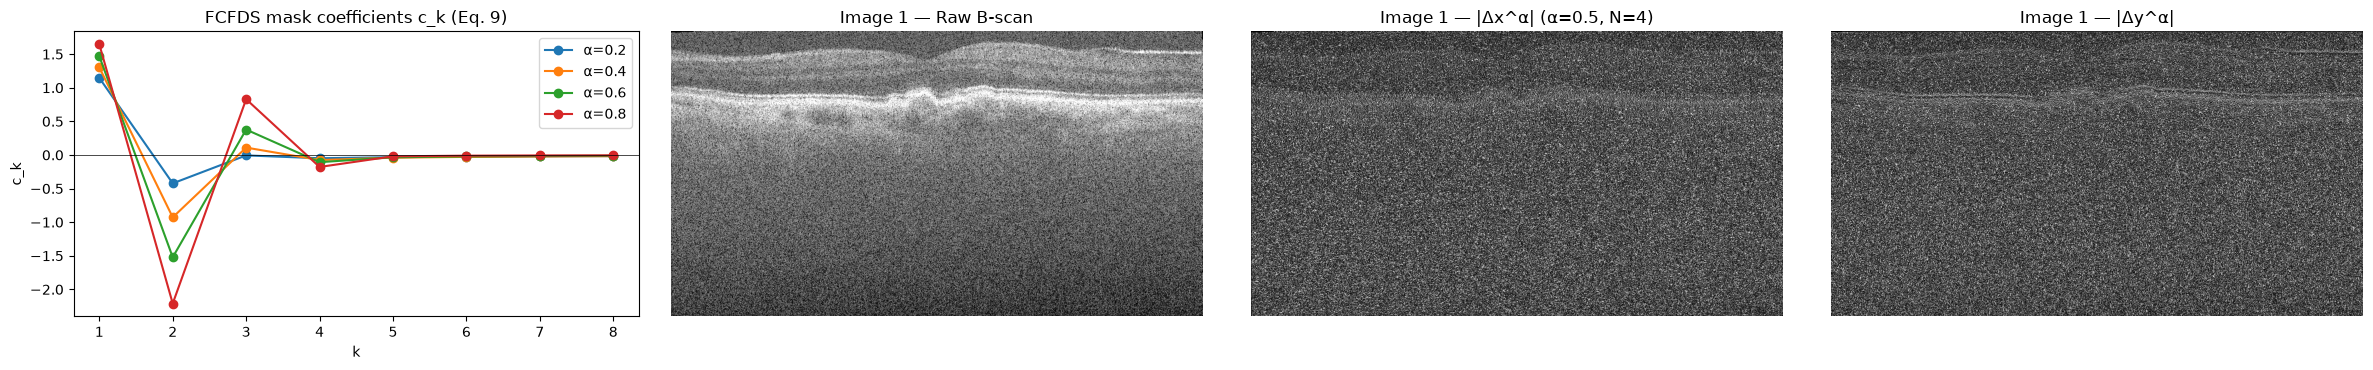

In [5]:
z_tune = load_gray(images.set_index("image").loc[TUNE_IMAGE, "raw"])
gx_map, gy_map = fcfds_gradients(z_tune)

fig, axes = plt.subplots(1, 4, figsize=(24, 3.8))
for a in [0.2, 0.4, 0.6, 0.8]:
    axes[0].plot(np.arange(1, 9), fcfds_coeffs(a, 8), marker="o", label=f"α={a}")
axes[0].axhline(0, color="k", lw=0.5)
axes[0].set(title="FCFDS mask coefficients c_k (Eq. 9)", xlabel="k", ylabel="c_k")
axes[0].legend()
for ax, (title, im) in zip(axes[1:], [("Raw B-scan", z_tune), (f"|Δx^α| (α={ALPHA}, N={N_TAPS})", np.abs(gx_map)),
                                       (f"|Δy^α|", np.abs(gy_map))]):
    ax.imshow(im, cmap="gray", vmax=np.percentile(im, 99))
    ax.set_title(f"{TUNE_IMAGE} — {title}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. FCFDS kernel and non-local means (Eqs. 10–13)

For a reference patch centred at $x$ and an offset $\Delta = (\sigma_x, \sigma_y)$ inside the $k\times k$ patch,

$$\mathfrak R(\Delta,x) = \exp\!\Big(-\frac{\sigma_x^2}{2\phi_x} - \frac{\sigma_y^2}{2\phi_y(\Delta,x)}\Big), \qquad
\phi_y(\Delta,x) = \frac{1}{1 + \big(|\Delta^\alpha_x| + |\Delta^\alpha_y|\big)/\eta}\Bigg|_{x+\Delta}.$$

$\phi_y$ is evaluated at the patch pixel $x+\Delta$ (it depends on both $\Delta$ and $x$) and uses magnitudes of the
fractional derivatives so that it stays in $(0, 1]$. In flat regions $\phi_y \to 1$; across a layer boundary the
derivatives are large, $\phi_y \to 0$ and the kernel ignores rows above / below the centre row, so patches are compared
mainly along the (horizontal) retinal layers.

The weight of candidate $t$ is $\omega(x,t) = \exp\!\big(-\sum_\Delta \mathfrak R(\Delta,x)\,(v(x+\Delta)-v(t+\Delta))^2/h^2\big)$.
The paper's Eq. 10 omits the square; without it the exponent can be negative (weights > 1), so the usual squared NLM
distance is used. The output is the weighted average over the $l\times l$ search window (Eq. 13).

**Implementation.** Because $\mathfrak R$ factorises into a horizontal Gaussian $e^{-\sigma_x^2/2\phi_x}$ and per-row
maps $A_{\sigma_y}(p) = e^{-\sigma_y^2/2\phi_y(p)}$, for every search offset the patch distance is
$\sum_{\sigma_x} e^{-\sigma_x^2/2\phi_x}\,\big[\sum_{\sigma_y} \text{shift}_{\sigma_y}(A_{\sigma_y}\cdot D)\big](x+\sigma_x)$
with $D$ the squared-difference image — fully vectorised over pixels. The uniform and isotropic-Gaussian kernels are
the special cases $A_{\sigma_y} = $ const.

In [6]:
OFFS = np.arange(-(PATCH // 2), PATCH // 2 + 1)


def noise_sigma(img):
    # MAD estimate from the finest diagonal Haar sub-band
    return np.median(np.abs(pywt.dwt2(img, "haar")[1][2])) / 0.6745


def fcfds_kernel(img, alpha=ALPHA, n_taps=N_TAPS, phi_x=PHI_X, eta=ETA):
    # Returns the vertical factor maps A (PATCH, H+2r, W+2r), the horizontal factor gx (PATCH,) and the φy map
    dx, dy = fcfds_gradients(img, alpha, n_taps)
    G = np.abs(dx) + np.abs(dy)
    eta = G.mean() if eta is None else eta
    phi_y = 1.0 / (1.0 + G / eta)
    phi_pad = np.pad(phi_y, PATCH // 2, mode="edge")
    A = np.exp(-OFFS[:, None, None] ** 2 / (2 * phi_pad[None]))
    return A, np.exp(-OFFS ** 2 / (2 * phi_x)), phi_y


def gaussian_kernel(phi=PHI_GAUSS):
    g = np.exp(-OFFS ** 2 / (2 * phi))
    return g[:, None, None], g


def uniform_kernel():
    return np.ones((PATCH, 1, 1)), np.ones(PATCH)


def kernel_mass(A, gx):
    return float(A.sum(axis=0).mean() * gx.sum())


def nlm(v, A, gx, h, search=SEARCH):
    r, s = PATCH // 2, search // 2
    H, W = v.shape
    vp = np.pad(v, s + r, mode="edge").astype(np.float32)      # Algorithm 1, step 3
    A, gx = A.astype(np.float32), gx.astype(np.float32)
    centre = vp[s:s + H + 2 * r, s:s + W + 2 * r]
    num = np.zeros((H, W), np.float32)
    den = np.zeros((H, W), np.float32)
    inv_h2 = np.float32(1.0 / h ** 2)
    for sy in range(-s, s + 1):
        for sx in range(-s, s + 1):
            cand = vp[s + sy:s + sy + H + 2 * r, s + sx:s + sx + W + 2 * r]
            D = (centre - cand) ** 2
            rows = np.zeros((H, W + 2 * r), np.float32)
            for i in range(PATCH):
                rows += (A[i] * D)[i:i + H]
            dist = np.zeros((H, W), np.float32)
            for i in range(PATCH):
                dist += gx[i] * rows[:, i:i + W]
            w = np.exp(-dist * inv_h2)
            num += w * cand[r:r + H, r:r + W]
            den += w
    return (num / den).astype(np.float64)


def make_kernel(img, kind, **kw):
    if kind == "fcfds":
        return fcfds_kernel(img, **kw)[:2]
    return gaussian_kernel(**kw) if kind == "gaussian" else uniform_kernel()


def nlm_denoise(img, kind, h_factor=None, h_abs=None, **kernel_kw):
    # Give either the normalised strength h_factor or an absolute h
    A, gx = make_kernel(img, kind, **kernel_kw)
    h = h_abs if h_abs is not None else h_factor * noise_sigma(img) * np.sqrt(kernel_mass(A, gx))
    return nlm(img, A, gx, h), h

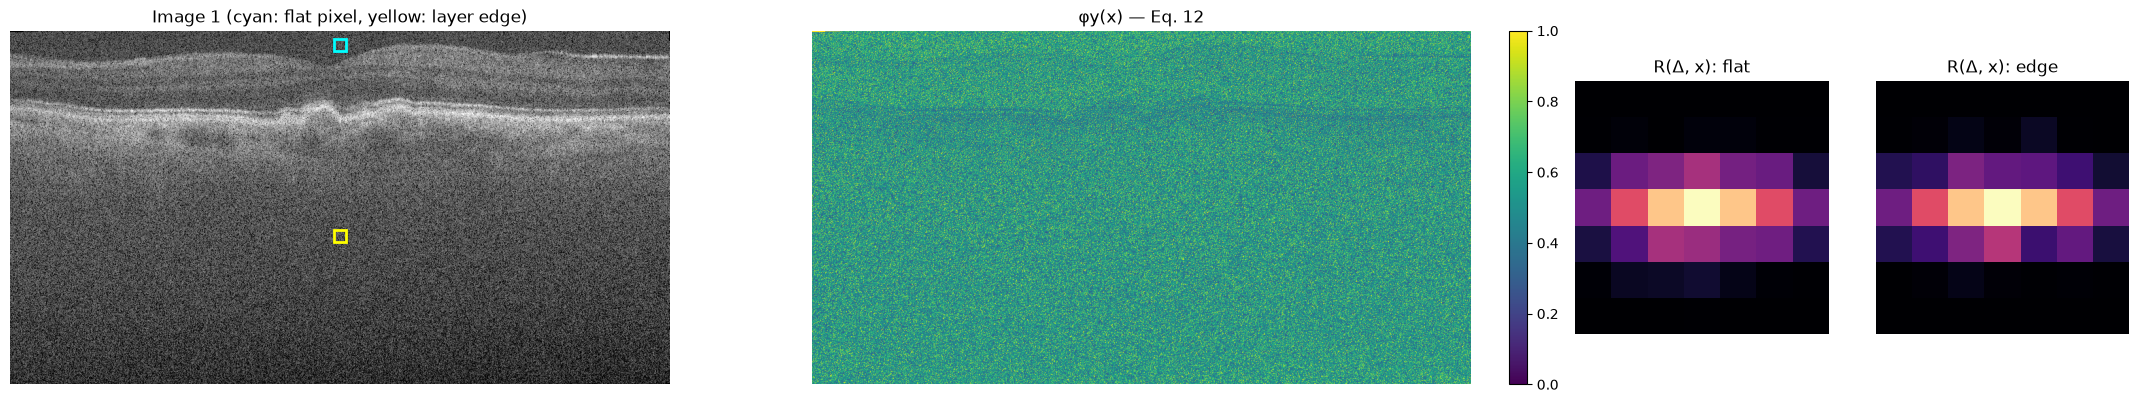

kernel mass: uniform 49.0, gaussian 21.4, FCFDS 8.5 (mean over pixels)


In [7]:
# What the FCFDS kernel looks like: φy over the tuning image and R(Δ, x) at a flat background pixel vs. on a layer edge
A_t, gx_t, phi_t = fcfds_kernel(z_tune)
r = PATCH // 2
grad_rows = np.abs(gy_map)
row_prof = grad_rows[:, z_tune.shape[1] // 2]
edge_pt = (int(np.argmax(row_prof)), z_tune.shape[1] // 2)
flat_pt = (20, z_tune.shape[1] // 2)


def kernel_at(pt):
    y, x = pt
    return np.array([[A_t[i, y + i, x + j] * gx_t[j] for j in range(PATCH)] for i in range(PATCH)])


fig, axes = plt.subplots(1, 4, figsize=(22, 4), gridspec_kw={"width_ratios": [3, 3, 1, 1]})
axes[0].imshow(z_tune, cmap="gray", vmin=0, vmax=MAX_VAL)
for (y, x), col in [(flat_pt, "cyan"), (edge_pt, "yellow")]:
    axes[0].plot(x, y, "s", ms=8, mfc="none", mec=col, mew=2)
axes[0].set_title(f"{TUNE_IMAGE} (cyan: flat pixel, yellow: layer edge)")
im = axes[1].imshow(phi_t, cmap="viridis", vmin=0, vmax=1)
axes[1].set_title("φy(x) — Eq. 12")
plt.colorbar(im, ax=axes[1], fraction=0.025)
for ax, pt, t in [(axes[2], flat_pt, "R(Δ, x): flat"), (axes[3], edge_pt, "R(Δ, x): edge")]:
    ax.imshow(kernel_at(pt), cmap="magma", vmin=0, vmax=1)
    ax.set_title(t)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()
print(f"kernel mass: uniform {kernel_mass(*uniform_kernel()):.1f}, gaussian {kernel_mass(*gaussian_kernel()):.1f}, "
      f"FCFDS {kernel_mass(A_t, gx_t):.1f} (mean over pixels)")

## 5. Metrics and parameter tuning

**PSNR / SSIM** are computed against the averaged image, as in the paper's Tables 3–4. SSIM uses a Gaussian window with
σ = 2 and the dynamic range of the denoised image.

**Tuning.** The paper gives no parameter values. $h_f$ is tuned separately for every kernel on `TUNE_IMAGE` only
(highest PSNR against its averaged image), and the sensitivity of the FCFDS kernel to α is checked at its best $h_f$.
The chosen values are then fixed for all 17 cases; summary means are reported over all cases and over the 16 cases not
used for tuning.

h grid:   0%|          | 0/18 [00:00<?, ?it/s]

tuning took 66s on Image 1; raw scan: {'PSNR': np.float64(17.281855565706003), 'SSIM': np.float64(0.06901418515666913)}


,h_factor,h,PSNR,SSIM
kernel,,,,
fcfds,3.6,318.3171,27.5024,0.4754
gaussian,2.0,281.2776,27.5966,0.4982
uniform,1.4,297.8503,27.6476,0.5233


,alpha,h_factor,PSNR,SSIM
0,0.3,3.6,27.5104,0.4750
1,0.5,3.6,27.5024,0.4754
2,0.8,3.6,27.4909,0.4762


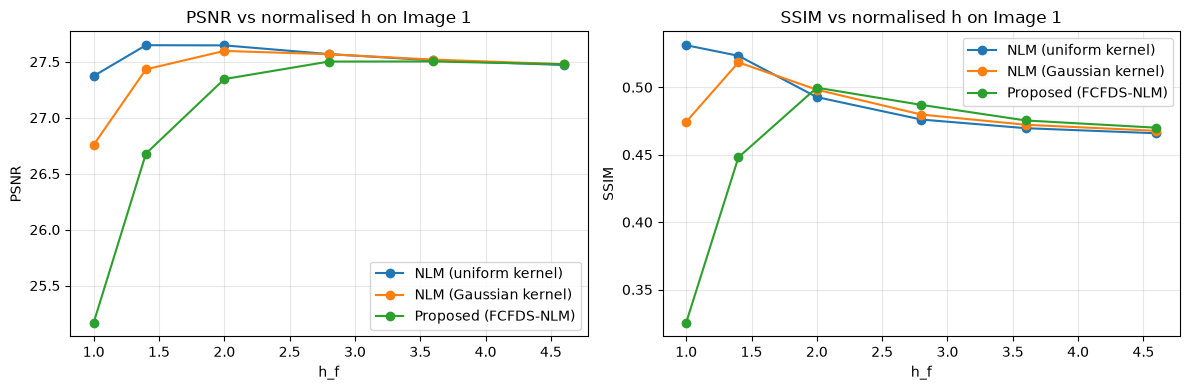

In [8]:
def psnr(ref, img, max_val=MAX_VAL):
    mse = np.mean((ref - img) ** 2)
    return np.inf if mse == 0 else 20 * np.log10(max_val / np.sqrt(mse))


def ssim(ref, img):
    return structural_similarity(ref, img, data_range=img.max() - img.min(), gaussian_weights=True, sigma=2.0,
                                 use_sample_covariance=False)


def metrics(ref, img):
    return {"PSNR": psnr(ref, img), "SSIM": ssim(ref, img)}


KINDS = {"uniform": "NLM (uniform kernel)", "gaussian": "NLM (Gaussian kernel)", "fcfds": "Proposed (FCFDS-NLM)"}

ref_tune = load_gray(images.set_index("image").loc[TUNE_IMAGE, "ref"])


def tune_run(kind, hf, **kw):
    out, h = nlm_denoise(z_tune, kind, h_factor=hf, **kw)
    return {"kernel": kind, "h_factor": hf, "h": h, **kw, **metrics(ref_tune, out)}


t0 = time.time()
jobs = [(kind, hf) for kind in KINDS for hf in H_GRID]
with ThreadPoolExecutor(N_WORKERS) as ex:
    tune_df = pd.DataFrame(list(tqdm(ex.map(lambda j: tune_run(*j), jobs), total=len(jobs), desc="h grid")))
best = tune_df.loc[tune_df.groupby("kernel")["PSNR"].idxmax()].set_index("kernel")
H_BEST = best["h_factor"].to_dict()

with ThreadPoolExecutor(N_WORKERS) as ex:
    alpha_df = pd.DataFrame(list(ex.map(lambda a: tune_run("fcfds", H_BEST["fcfds"], alpha=a), ALPHA_GRID)))
print(f"tuning took {time.time() - t0:.0f}s on {TUNE_IMAGE}; raw scan: {metrics(ref_tune, z_tune)}")
display(best[["h_factor", "h", "PSNR", "SSIM"]].round(4))
display(alpha_df[["alpha", "h_factor", "PSNR", "SSIM"]].round(4))
tune_df.to_csv(OUT_DIR / "tuning.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for kind, grp in tune_df.groupby("kernel", sort=False):
    for ax, m in zip(axes, ["PSNR", "SSIM"]):
        ax.plot(grp["h_factor"], grp[m], marker="o", label=KINDS[kind])
for ax, m in zip(axes, ["PSNR", "SSIM"]):
    ax.set(title=f"{m} vs normalised h on {TUNE_IMAGE}", xlabel="h_f", ylabel=m)
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

## 6. Walk-through (cf. Figs. 2 and 3)

All methods on two held-out cases. `run_methods` produces every output compared in the tables for one B-scan.

2 demo images in 22.0s


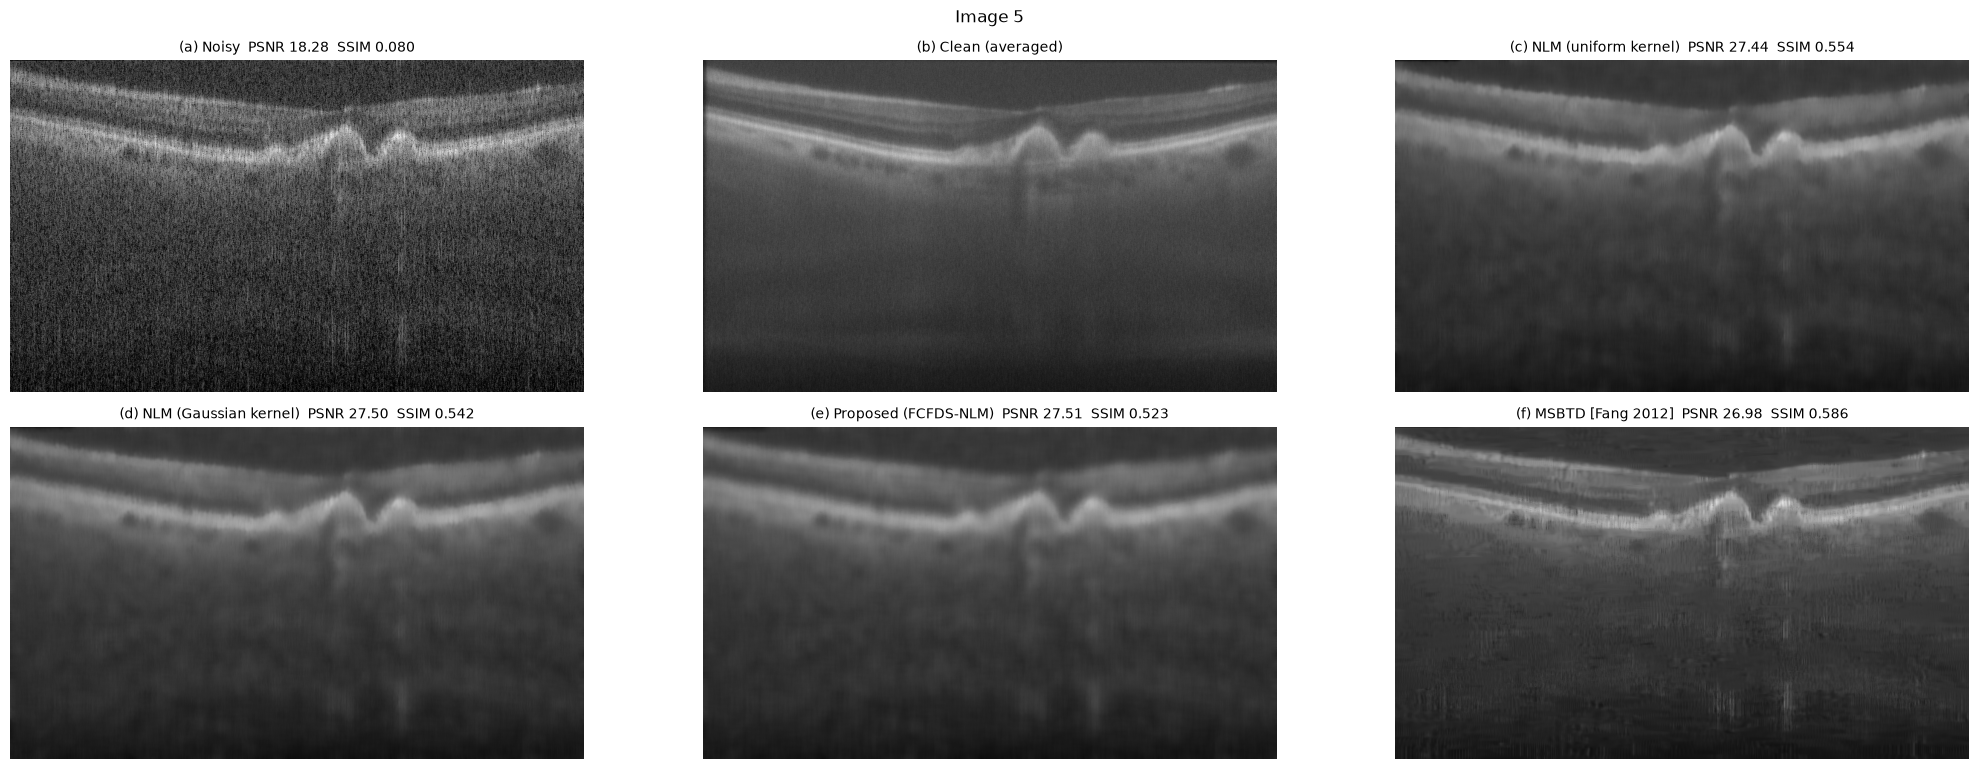

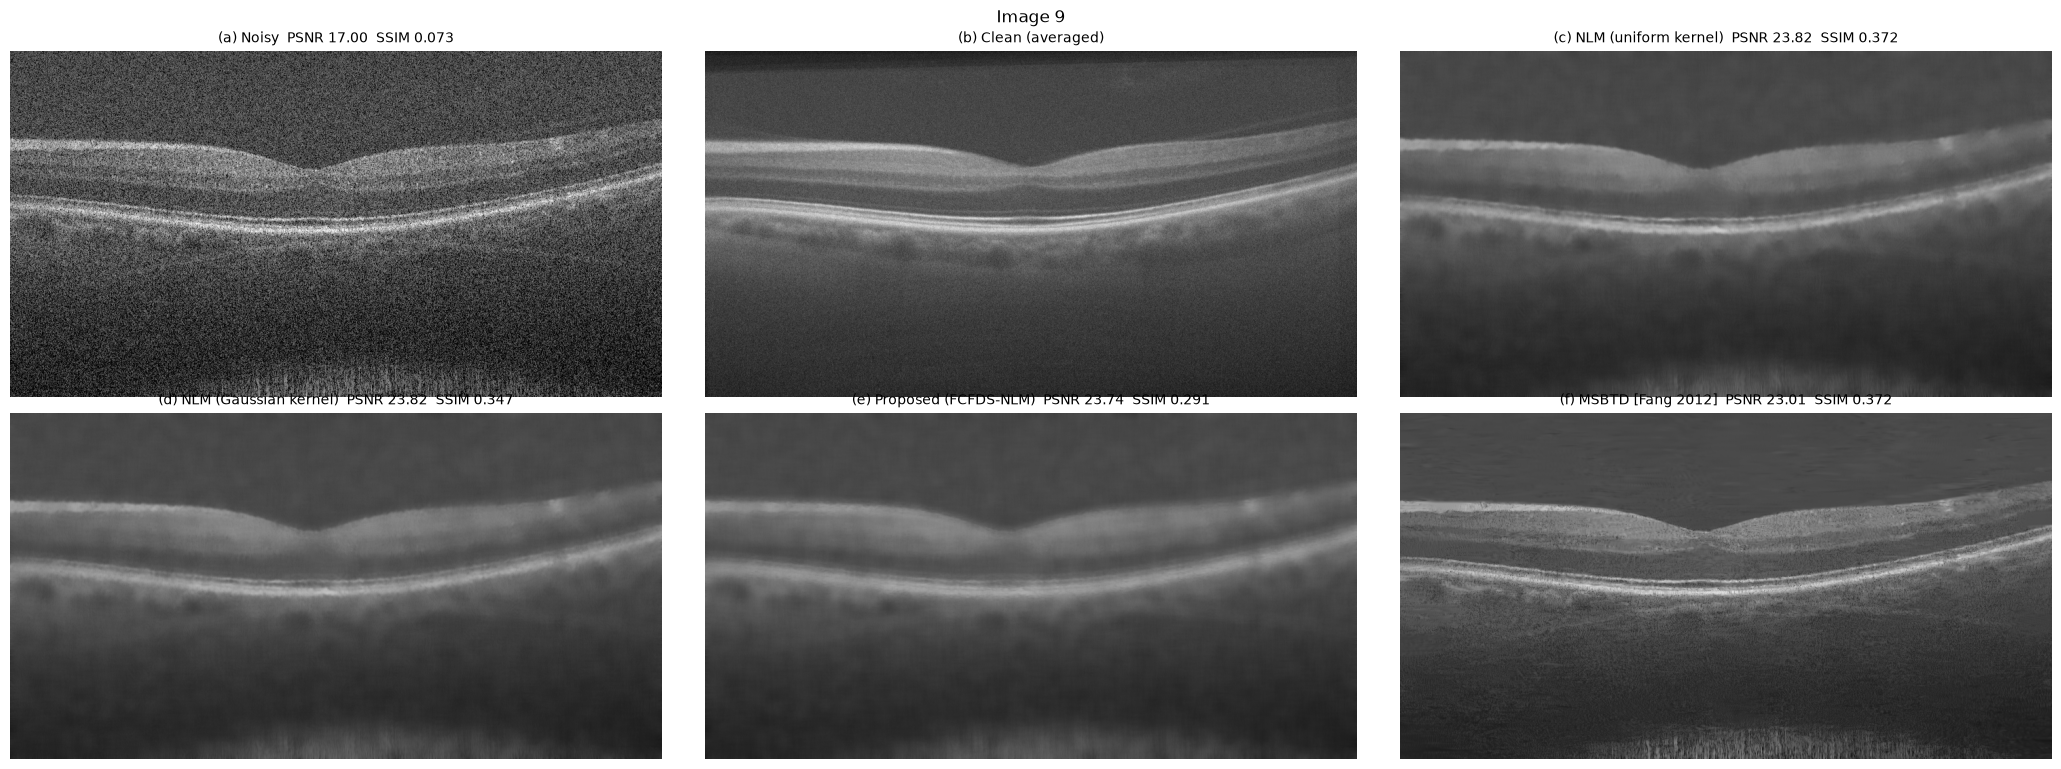

In [9]:
MSBTD = "MSBTD [Fang 2012]"


def run_methods(row):
    z = load_gray(row["raw"])
    outputs = {"Noisy": z}
    for kind, name in KINDS.items():
        outputs[name] = nlm_denoise(z, kind, h_factor=H_BEST[kind])[0]
    msbtd = optional(row, "msbtd", load_msbtd)
    if msbtd is not None:
        outputs[MSBTD] = msbtd
    return outputs


demo_rows = [images[images["image"] == name].iloc[0] for name in DEMO_IMAGES]
t0 = time.time()
with ThreadPoolExecutor(N_WORKERS) as ex:
    demo_out = list(ex.map(run_methods, demo_rows))
print(f"{len(demo_rows)} demo images in {time.time() - t0:.1f}s")

for row, outs in zip(demo_rows, demo_out):
    ref = load_gray(row["ref"])
    panels = [("Noisy", outs["Noisy"]), ("Clean (averaged)", ref)] + [(k, v) for k, v in outs.items() if k != "Noisy"]
    n_cols = 3
    n_rows = int(np.ceil(len(panels) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(7 * n_cols, 3.9 * n_rows))
    for i, (ax, (title, im)) in enumerate(zip(axes.flat, panels)):
        m = "" if title.startswith("Clean") else "  PSNR {PSNR:.2f}  SSIM {SSIM:.3f}".format(**metrics(ref, im))
        ax.imshow(im, cmap="gray", vmin=0, vmax=MAX_VAL)
        ax.set_title(f"({chr(ord('a') + i)}) {title}{m}", fontsize=10)
    for ax in axes.flat:
        ax.axis("off")
    fig.suptitle(row["image"])
    plt.tight_layout()
    plt.savefig(OUT_DIR / f"walkthrough_{row['image'].replace(' ', '_')}.png", dpi=100)
    plt.show()

## 7. Kernel ablation (cf. Figs. 4–5)

The paper compares the uniform and FCFDS kernels with "the same algorithm and parameters". Two readings are run:

* **Same absolute h** — the FCFDS-tuned $h$ is reused unchanged for the uniform kernel (the paper's protocol).
  Because the uniform kernel sums 49 squared differences while the FCFDS kernel has a much smaller mass, the same $h$
  means far weaker smoothing for the uniform kernel.
* **h tuned per kernel** — each kernel uses its own best $h_f$ from Section 5.

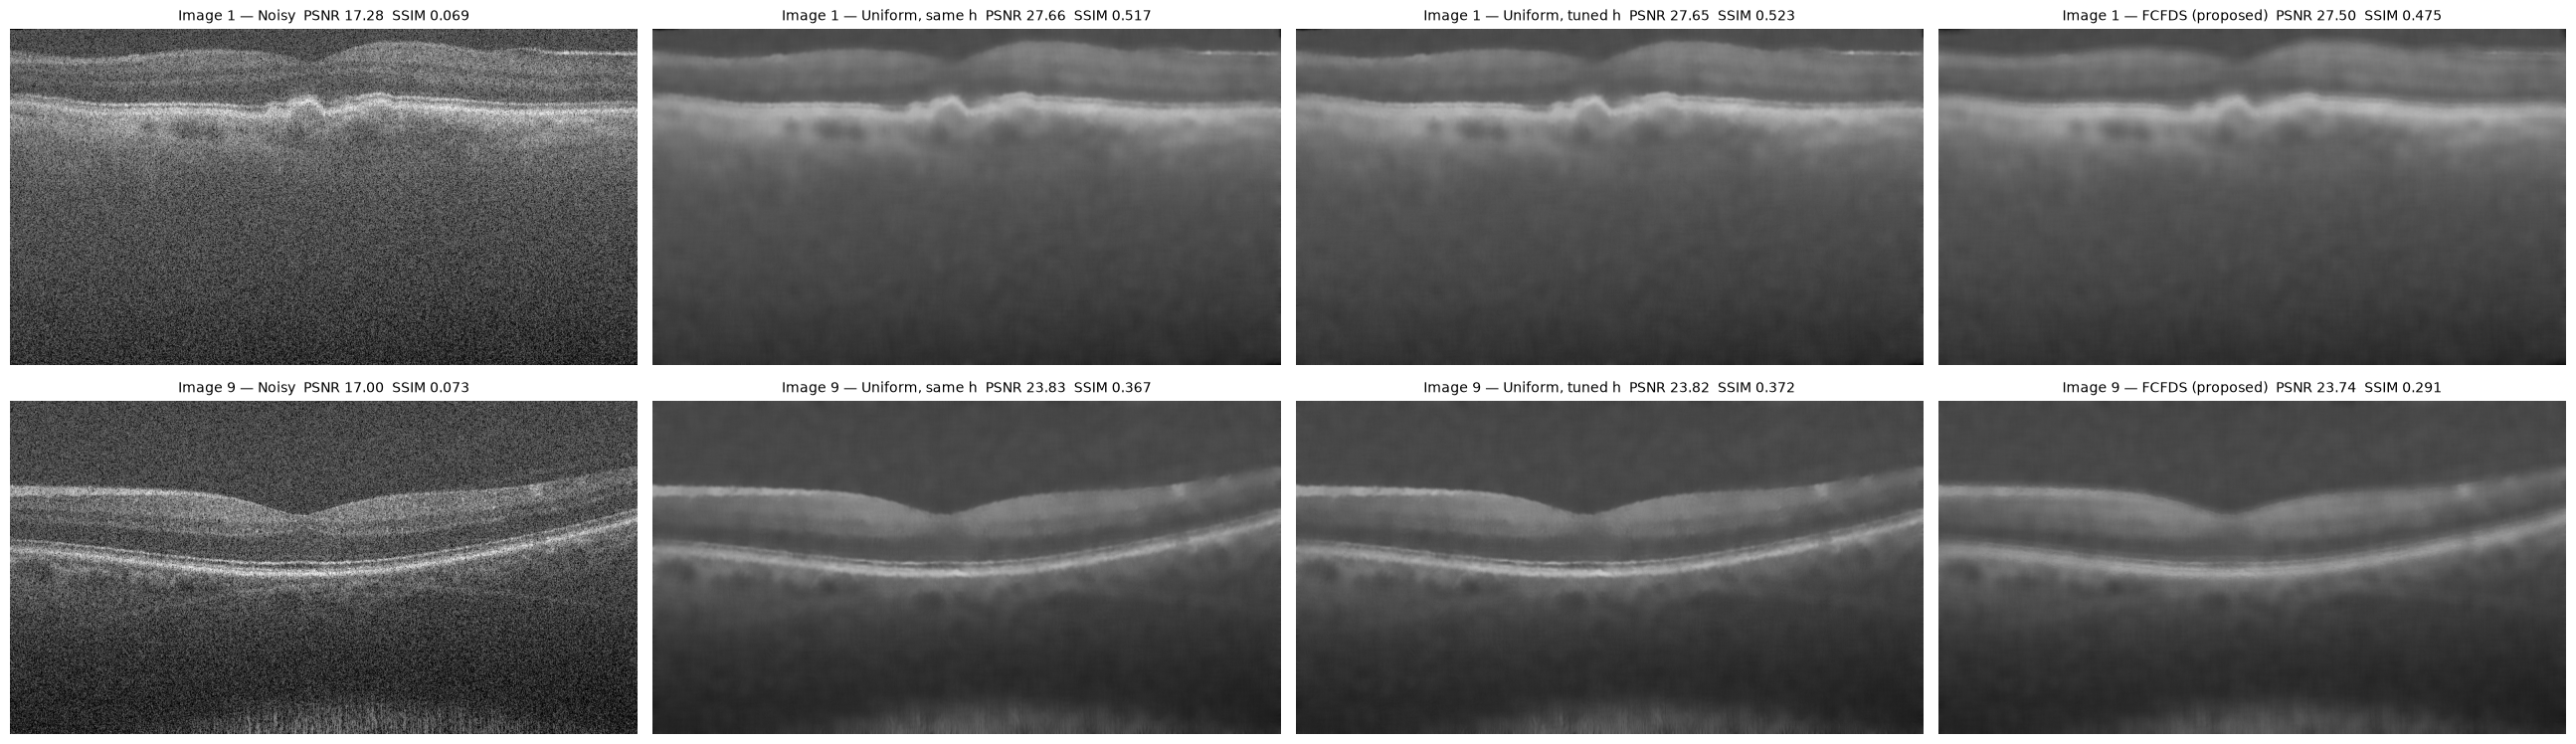

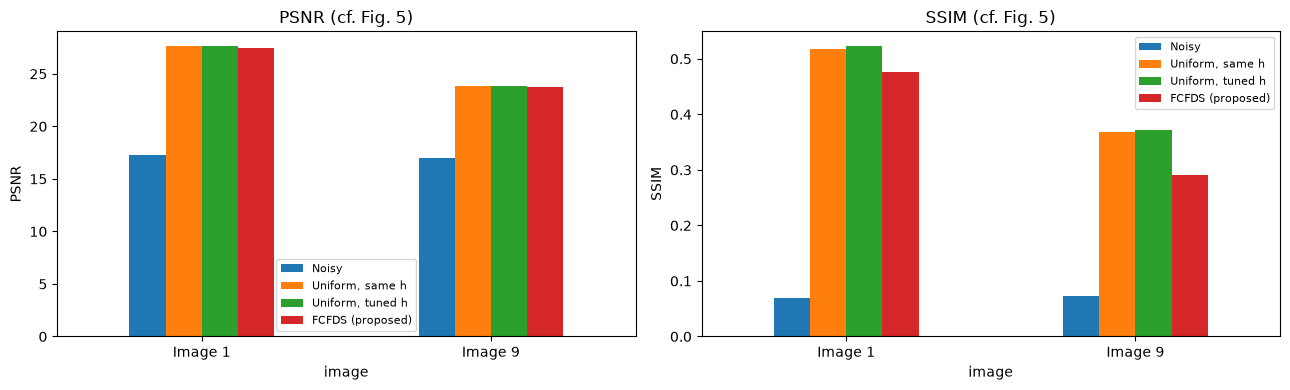

In [10]:
ABL_IMAGES = ["Image 1", "Image 9"]


def ablation(name):
    row = images[images["image"] == name].iloc[0]
    z, ref = load_gray(row["raw"]), load_gray(row["ref"])
    prop, h_prop = nlm_denoise(z, "fcfds", h_factor=H_BEST["fcfds"])
    outs = {"Noisy": z,
            "Uniform, same h": nlm_denoise(z, "uniform", h_abs=h_prop)[0],
            "Uniform, tuned h": nlm_denoise(z, "uniform", h_factor=H_BEST["uniform"])[0],
            "FCFDS (proposed)": prop}
    return name, z, ref, outs


with ThreadPoolExecutor(N_WORKERS) as ex:
    abl = list(ex.map(ablation, ABL_IMAGES))

fig, axes = plt.subplots(len(abl), 4, figsize=(26, 3.9 * len(abl)))
abl_rows = []
for r_i, (name, z, ref, outs) in enumerate(abl):
    for c_i, (title, im) in enumerate(outs.items()):
        m = metrics(ref, im)
        abl_rows.append({"image": name, "variant": title, **m})
        axes[r_i, c_i].imshow(im, cmap="gray", vmin=0, vmax=MAX_VAL)
        axes[r_i, c_i].set_title(f"{name} — {title}  PSNR {m['PSNR']:.2f}  SSIM {m['SSIM']:.3f}", fontsize=10)
        axes[r_i, c_i].axis("off")
plt.tight_layout()
plt.savefig(OUT_DIR / "fig4_kernel_ablation.png", dpi=100)
plt.show()

abl_df = pd.DataFrame(abl_rows)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, m in zip(axes, ["PSNR", "SSIM"]):
    abl_df.pivot(index="image", columns="variant", values=m)[list(abl[0][3])].plot.bar(ax=ax, rot=0)
    ax.set(title=f"{m} (cf. Fig. 5)", ylabel=m)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 8. All 17 cases (Tables 3–4)

In [11]:
def process(row):
    outputs = run_methods(row)
    ref = load_gray(row["ref"])
    recs = [{"image": row["image"], "method": m, **metrics(ref, d)} for m, d in outputs.items()]
    if SAVE_DENOISED:
        stem = row["image"].replace(" ", "_")
        for kind, name in KINDS.items():
            Image.fromarray(np.clip(np.round(outputs[name]), 0, 255).astype(np.uint8)).save(
                OUT_DIR / "denoised" / f"{stem}_nlm_{kind}.png")
    return recs


if SAVE_DENOISED:
    (OUT_DIR / "denoised").mkdir(exist_ok=True)
t0 = time.time()
with ThreadPoolExecutor(N_WORKERS) as ex:
    recs = list(tqdm(ex.map(process, [r for _, r in images.iterrows()]), total=len(images), desc="images"))
print(f"all images in {time.time() - t0:.0f}s")

results = pd.DataFrame([r for rs in recs for r in rs])
results.to_csv(OUT_DIR / "metrics_per_image.csv", index=False)
method_order = [m for m in ["Noisy", *KINDS.values(), MSBTD] if m in set(results["method"])]

images:   0%|          | 0/17 [00:00<?, ?it/s]

all images in 166s


In [12]:
# Reload the loop's saved results when the kernel was restarted, so the cells below work without re-running NLM.
if "results" not in globals():
    results = pd.read_csv(OUT_DIR / "metrics_per_image.csv")
    method_order = [m for m in ["Noisy", *KINDS.values(), MSBTD] if m in set(results["method"])]
    print(f"Loaded saved results from {OUT_DIR}: {results['image'].nunique()} images, {len(method_order)} methods")


def per_image_table(metric):
    table = results.pivot(index="image", columns="method", values=metric)[method_order]
    table = table.loc[results["image"].unique()]
    mean, std, held_mean = table.mean(), table.std(), table.drop(index=TUNE_IMAGE).mean()
    table.loc["Mean"] = mean
    table.loc["Standard Deviation"] = std
    table.loc[f"Mean (excl. {TUNE_IMAGE})"] = held_mean
    return table


for metric in ["PSNR", "SSIM"]:
    print(f"\n=== Table {3 if metric == 'PSNR' else 4} — {metric} against the averaged image ===")
    display(per_image_table(metric).round(4))


=== Table 3 — PSNR against the averaged image ===


method,Noisy,NLM (uniform kernel),NLM (Gaussian kernel),Proposed (FCFDS-NLM),MSBTD [Fang 2012]
image,,,,,
Image 1,17.2819,27.6476,27.5966,27.5024,26.7869
Image 2,17.9002,28.4482,28.1915,27.7266,28.0406
Image 3,17.8048,28.2510,28.2584,28.1636,27.6563
Image 4,17.5636,25.9557,25.9128,25.7853,25.5772
Image 5,18.2835,27.4421,27.5008,27.5081,26.9810
Image 6,18.0775,29.5420,29.5674,29.5534,27.8974
Image 7,18.2872,30.7033,30.4919,30.1343,29.9691
Image 8,18.2249,29.3744,29.1768,28.7779,28.6256
Image 9,17.0012,23.8223,23.8213,23.7447,23.0146



=== Table 4 — SSIM against the averaged image ===


method,Noisy,NLM (uniform kernel),NLM (Gaussian kernel),Proposed (FCFDS-NLM),MSBTD [Fang 2012]
image,,,,,
Image 1,0.0690,0.5233,0.4982,0.4754,0.5123
Image 2,0.0879,0.5953,0.5561,0.5271,0.5949
Image 3,0.0771,0.4766,0.4540,0.4339,0.4788
Image 4,0.0759,0.5915,0.5654,0.5149,0.5317
Image 5,0.0802,0.5544,0.5424,0.5233,0.5864
Image 6,0.0708,0.5188,0.4934,0.4507,0.5247
Image 7,0.0840,0.4995,0.4685,0.4268,0.4889
Image 8,0.0900,0.6337,0.6014,0.5749,0.6151
Image 9,0.0731,0.3721,0.3473,0.2908,0.3720


PSNR            SSIM        
                          mean     std    mean     std
method                                                
Noisy                  17.7437  0.3810  0.0836  0.0082
NLM (uniform kernel)   27.6030  1.8617  0.5552  0.0692
NLM (Gaussian kernel)  27.5144  1.8262  0.5308  0.0693
Proposed (FCFDS-NLM)   27.2725  1.7799  0.5009  0.0760
MSBTD [Fang 2012]      26.7643  2.0010  0.5170  0.0656

FCFDS − NLM (uniform kernel)   PSNR: mean -0.3421, wins on 2/16 held-out cases
FCFDS − NLM (uniform kernel)   SSIM: mean -0.0546, wins on 0/16 held-out cases
FCFDS − NLM (Gaussian kernel)  PSNR: mean -0.2512, wins on 1/16 held-out cases
FCFDS − NLM (Gaussian kernel)  SSIM: mean -0.0304, wins on 0/16 held-out cases

DUKE means reported in the paper (Tables 3–4)


,PSNR,SSIM
Noisy,27.8513,0.0866
NCDF,25.8830,0.4828
WGLRR,29.2269,0.7020
PNLM,28.4428,0.6651
PBFD,29.1516,0.6919
Proposed,29.0425,0.6983


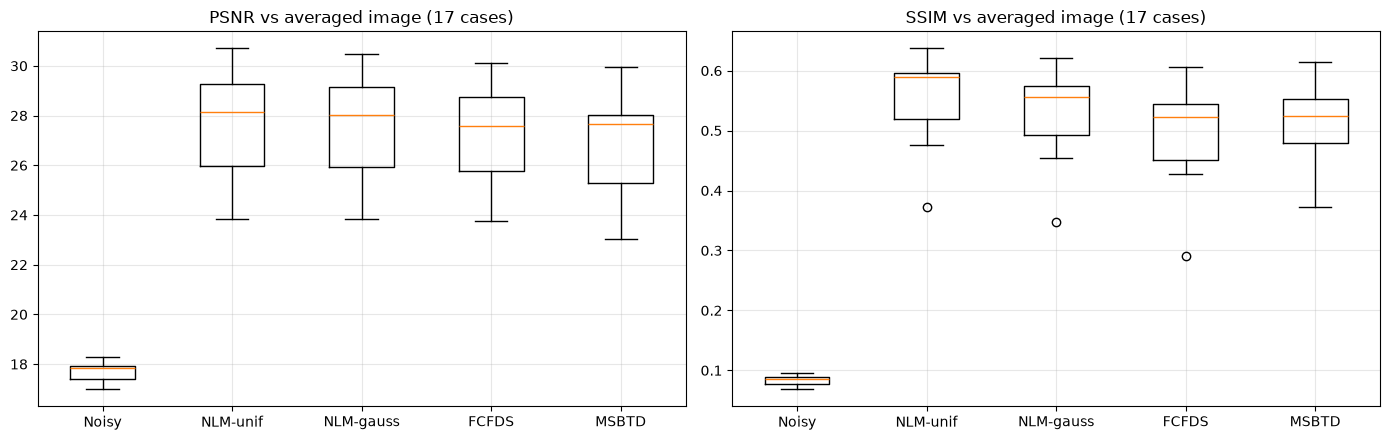

In [13]:
summary = results.groupby("method")[["PSNR", "SSIM"]].agg(["mean", "std"]).loc[method_order]
summary.to_csv(OUT_DIR / "metrics_summary.csv")
display(summary.round(4))

# Paired comparison of the proposed kernel with the two classical kernels over the held-out cases
held = results[results["image"] != TUNE_IMAGE].pivot(index="image", columns="method", values=["PSNR", "SSIM"])
for base in [KINDS["uniform"], KINDS["gaussian"]]:
    for m in ["PSNR", "SSIM"]:
        diff = held[(m, KINDS["fcfds"])] - held[(m, base)]
        print(f"FCFDS − {base:<22} {m}: mean {diff.mean():+.4f}, wins on {(diff > 0).sum()}/{len(diff)} held-out cases")

paper = pd.DataFrame({"PSNR": [27.8513, 25.8830, 29.2269, 28.4428, 29.1516, 29.0425],
                      "SSIM": [0.0866, 0.4828, 0.7020, 0.6651, 0.6919, 0.6983]},
                     index=["Noisy", "NCDF", "WGLRR", "PNLM", "PBFD", "Proposed"])
print("\nDUKE means reported in the paper (Tables 3–4)")
display(paper)

short = {"Noisy": "Noisy", KINDS["uniform"]: "NLM-unif", KINDS["gaussian"]: "NLM-gauss", KINDS["fcfds"]: "FCFDS",
         MSBTD: "MSBTD"}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, metric in zip(axes, ["PSNR", "SSIM"]):
    ax.boxplot([results.loc[results["method"] == m, metric] for m in method_order],
               tick_labels=[short[m] for m in method_order])
    ax.set_title(f"{metric} vs averaged image (17 cases)")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUT_DIR / "metrics_boxplot.png", dpi=110)
plt.show()

## 9. Edge detection on the denoised images (cf. Fig. 6)

Canny edges (σ = 2, same thresholds for every image) on the second walk-through case. Speckle that survives denoising
shows up as scattered edges in the vitreous and choroid; over-smoothing removes the weak inner-layer boundaries.

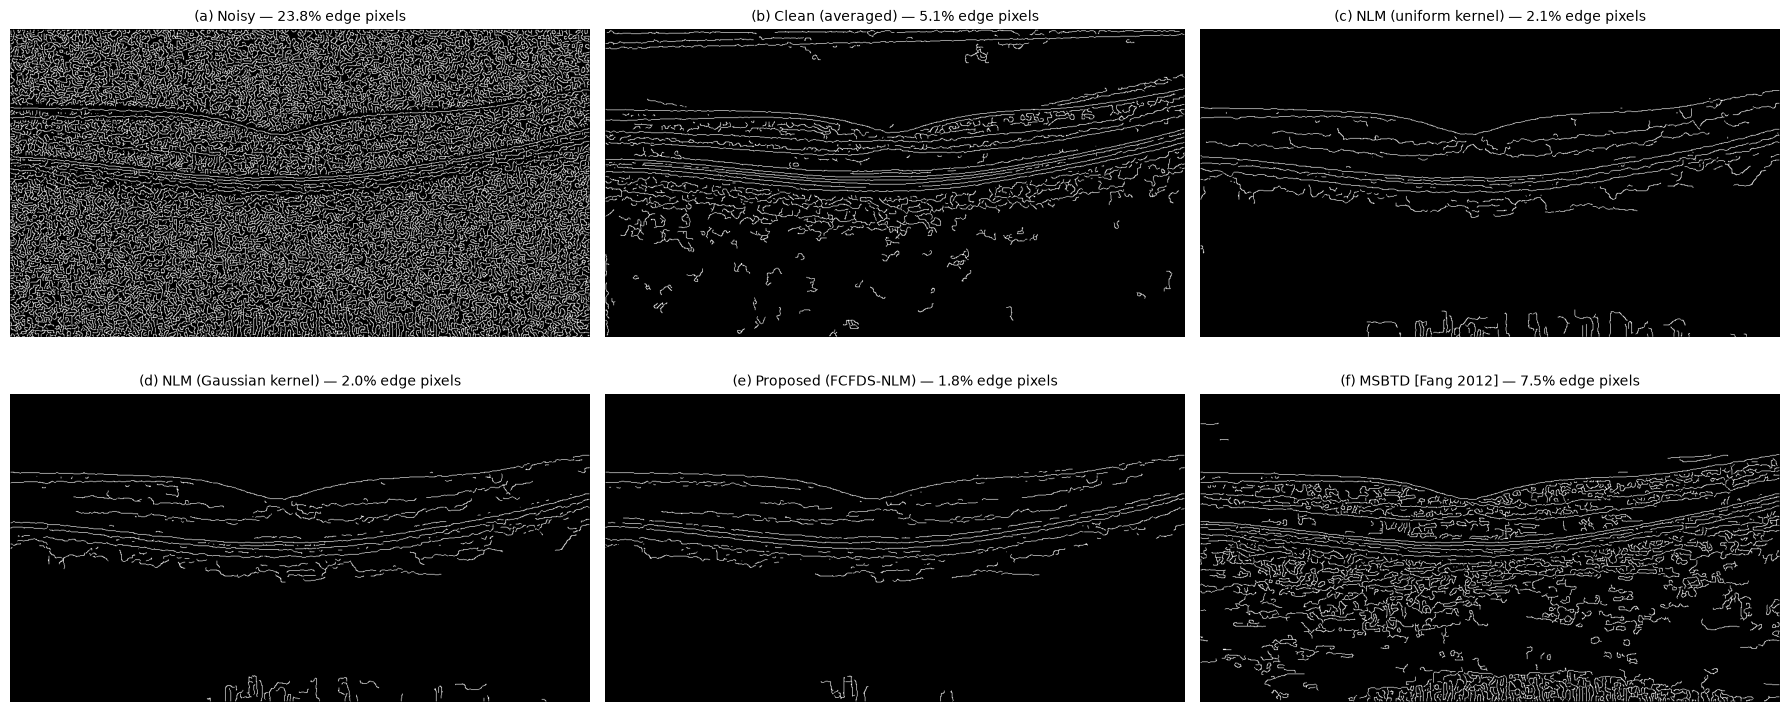

In [14]:
row, outs = demo_rows[-1], demo_out[-1]
panels = [("Noisy", outs["Noisy"]), ("Clean (averaged)", load_gray(row["ref"]))]
panels += [(k, v) for k, v in outs.items() if k != "Noisy"]
fig, axes = plt.subplots(int(np.ceil(len(panels) / 3)), 3, figsize=(18, 3.9 * int(np.ceil(len(panels) / 3))))
for i, (ax, (title, im)) in enumerate(zip(axes.flat, panels)):
    edges = canny(im / MAX_VAL, sigma=2.0, low_threshold=0.02, high_threshold=0.05)
    ax.imshow(edges, cmap="gray")
    ax.set_title(f"({chr(ord('a') + i)}) {title} — {edges.mean():.1%} edge pixels", fontsize=10)
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.savefig(OUT_DIR / "fig6_canny.png", dpi=100)
plt.show()


## 10. Findings

* **FCFDS operator.** With the corrected $\rho_2$ the weights sum to 1, and a long FCFDS mask reproduces the analytic
  Riemann–Liouville derivative of $x^2$ exactly, so the operator itself is implemented correctly. With $N = 4$ taps the
  masks act as short fractional edge detectors (Section 3 figure), and $\phi_y$ drops on the retinal layer boundaries
  as intended (Section 4 figure).
* **Denoising.** All three NLM variants raise PSNR from about 17.7 dB (raw) to 27.3–27.6 dB and SSIM from 0.08 to
  0.50–0.56, ahead of MSBTD on PSNR (26.76 dB). But **the FCFDS kernel did not beat the classical kernels** on this
  dataset. When h is tuned separately for each kernel, it trails the uniform kernel by 0.34 dB PSNR and 0.055 SSIM on
  average over the 16 held-out cases, and it never wins on SSIM. Its parameters hardly matter: α ∈ {0.3, 0.5, 0.8}
  changes PSNR by < 0.02 dB.
* **Why.** Eq. 12 limits $\phi_y \le 1$ px², so the FCFDS kernel effectively uses only about 3 rows of the 7×7 patch
  (mean mass 8.5 vs 49 for uniform). Under heavy speckle, the smaller effective patch makes patch distances noisier,
  and that costs more than avoiding mixing across layers gains. A prototype with a larger vertical variance,
  $\phi_y = \phi_0/(1+G/\eta)$ with $\phi_0 = 16$, only tied the uniform kernel (27.66 vs 27.65 dB on Image 1).
* **Ablation (Figs. 4–5).** With the same absolute h, the uniform kernel was *not* under-smoothed here (27.66 vs
  27.50 dB on Image 1), because the tuned h values of the two kernels are similar. The large gap in the paper's
  Figs. 4–5 most likely comes from an h that is small relative to the uniform kernel's 49-term distance. The paper
  does not report its h, so this cannot be checked.
* **Absolute numbers vs. the paper.** The paper reports 27.85 dB PSNR for the *noisy* DUKE images, whereas the raw
  scans here score 17.74 dB against the averaged images. The paper must have used a different normalisation or
  reference, so only the ranking of methods carries over, not the absolute values.
